# 04 · Engenharia de atributos

**Objetivo:** construir os atributos dos modelos com a **garantia de que nenhum usa informação indisponível na data da previsão**, e medir o valor de cada grupo, em especial das dummies obrigatórias.

| Grupo | Atributos | Disponibilidade na origem T | Módulo |
|---|---|---|---|
| Temporais | dia da semana, dia do mês, mês, semana do ano, fim de semana, feriado, data comercial, início do mês, Fourier semanal (ordem 2) | determinísticos | `temporal_features.py` |
| Defasagens | `lag_1, 2, 3, 7, 14, 21, 28` | até d − 1; no horizonte, a recursão usa as próprias previsões | `lag_features.py` |
| Janelas móveis | média, desvio e CV de 7, 14 e 30 dias (terminando em d − 1) | idem | `lag_features.py` |
| Tendência | `tempo` (dias desde 01/03/2024) | determinístico | `feature_pipeline.py` |
| **Dummies de quebra** | `dummy_horario_reduzido`, `dummy_novos_clientes`, `regime_*`, `maquinas_ativas` (Total) | **redetectadas só com dados até T** | `break_dummies.py` |
| Comportamentais | média de 7 dias de: % de vendas de manhã (≤ 9h) e à noite (≥ 20h), ticket médio, itens por pedido; na M1, cartões únicos e % de cartões novos | até d − 1; **congeladas no valor de T** para d > T + 1 | `feature_pipeline.py` |

**Por que não usar defasagens da receita no modelo de demanda e vice-versa?** Na previsão recursiva de 14 dias, a defasagem da *outra* variável teria de ser prevista também (um sistema multivariado). Cada alvo usa as próprias defasagens. A relação entre volume e preço entra pelos comportamentais (ticket médio) e pelo modelo de contagem, que gera a receita a partir da demanda.

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

from src.visualization.plots import aplicar_tema
aplicar_tema()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")


def mostrar(fig):
    """Exibe a figura uma única vez e libera a memória."""
    display(fig)
    plt.close(fig)

from src.data.preprocessing import preparar_base
from src.structural_breaks.structural_break_test import DetectorQuebras
from src.features import feature_pipeline as fp
from src.features.break_dummies import dummies_quebras
from src.visualization.plots import cor_serie, anotar_quebras, formatar_eixo_datas, CORES

base = preparar_base()
det = DetectorQuebras(base.series, base.transacoes)
ORIGEM = pd.Timestamp("2025-03-09")

2026-11-10 19:10:15 | INFO    | src.data.load_data | Dados brutos conferidos com o MANIFEST.json (SHA-256)


2026-11-10 19:10:15 | INFO    | src.data.load_data | index_1.csv: 3636 registros válidos (máquina 1)


2026-11-10 19:10:15 | INFO    | src.data.load_data | index_2.csv: 262 registros válidos (máquina 2)


2026-11-10 19:10:16 | INFO    | src.data.preprocessing | Séries diárias construídas: {('Máquina 1', 'demanda'): 388, ('Máquina 1', 'receita'): 388, ('Máquina 2', 'demanda'): 44, ('Máquina 2', 'receita'): 44, ('Total', 'demanda'): 388, ('Total', 'receita'): 388}


## 1. Matriz de atributos (Máquina 1, últimos dias do treino)

In [2]:
c = fp.ConstrutorAtributos(base, det, "Máquina 1", ORIGEM)
X = c(base.series[("Máquina 1", "demanda")].loc[:ORIGEM])
print(X.shape)
display(X.tail(4).T)

(374, 39)


data,2025-03-06,2025-03-07,2025-03-08,2025-03-09
lag_1,19.000,12.000,17.000,8.000
lag_2,16.000,19.000,12.000,17.000
lag_3,22.000,16.000,19.000,12.000
lag_7,19.000,17.000,8.000,6.000
lag_14,19.000,23.000,5.000,6.000
lag_21,13.000,15.000,9.000,10.000
lag_28,12.000,16.000,8.000,9.000
media_7,15.286,14.286,14.286,14.286
dp_7,5.992,5.851,5.851,5.851
cv_7,0.392,0.410,0.410,0.410


## 2. As dummies obrigatórias

As datas vêm do notebook 03, detectadas só com o treino. O gráfico mostra as duas dummies sobre a demanda da M1.

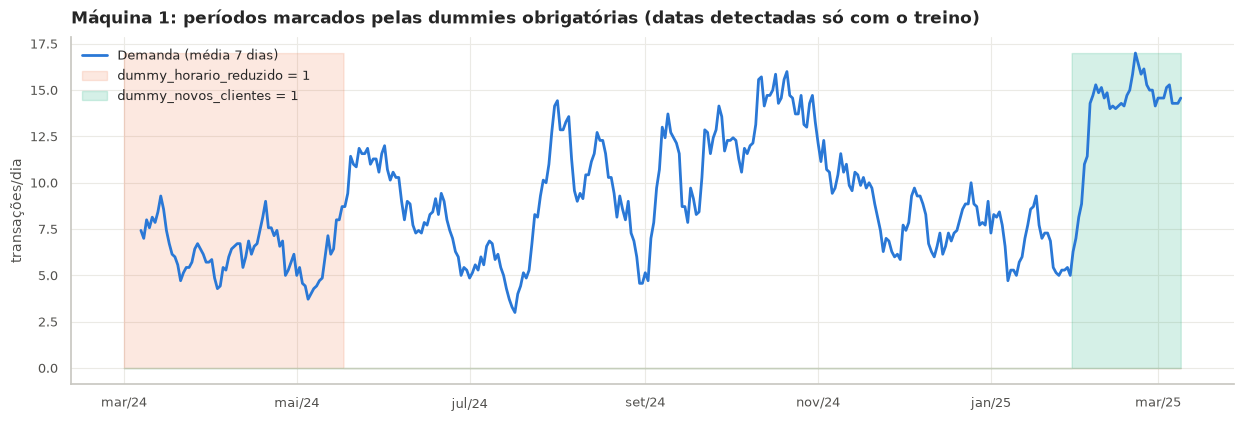

,dummy_horario_reduzido,dummy_novos_clientes,regime_240724,regime_161124
data,,,,
2024-05-16,1,0,0,0
2024-05-17,1,0,0,0
2024-05-18,0,0,0,0
2025-01-29,0,0,1,1
2025-01-30,0,1,1,1


In [3]:
y = base.series[("Máquina 1", "demanda")].loc[:ORIGEM]
D = dummies_quebras(y.index, "Máquina 1", ORIGEM, det, base.inicio["Máquina 2"])
fig, ax = plt.subplots(figsize=(15, 4.5))
ax.plot(y.index, y.rolling(7, min_periods=7).mean(), color=cor_serie("Máquina 1"), lw=2, label="Demanda (média 7 dias)")
ax2_y = y.rolling(7, min_periods=7).mean().max()
ax.fill_between(y.index, 0, ax2_y * D["dummy_horario_reduzido"], color=CORES["Máquina 2"], alpha=0.15, step="mid", label="dummy_horario_reduzido = 1")
ax.fill_between(y.index, 0, ax2_y * D["dummy_novos_clientes"], color=CORES["Total"], alpha=0.18, step="mid", label="dummy_novos_clientes = 1")
ax.set_ylabel("transações/dia")
ax.set_title("Máquina 1: períodos marcados pelas dummies obrigatórias (datas detectadas só com o treino)")
ax.legend(loc="upper left")
formatar_eixo_datas(ax)
mostrar(fig)
display(D.loc[["2024-05-16", "2024-05-17", "2024-05-18", "2025-01-29", "2025-01-30"]])

**Origens antigas não enxergam o futuro.** Numa origem de out/2024, a quebra de 2025 ainda não aconteceu, e a dummy não existe:

In [4]:
for o in ["2024-10-20", "2025-01-26", "2025-02-09", "2025-02-23", "2025-03-09"]:
    o = pd.Timestamp(o)
    print(f"origem {o:%d/%m/%Y}: horário reduzido até {det.janela_ate('Máquina 1', o):%d/%m/%Y} | "
          f"novos clientes desde {det.quebra_novos_clientes_ate('Máquina 1', o) or '— (ainda não detectável)'} | "
          f"regimes: {[f'{q:%d/%m/%y}' for q in det.quebras_ate('Máquina 1', o)]}")

origem 20/10/2024: horário reduzido até 18/05/2024 | novos clientes desde — (ainda não detectável) | regimes: ['24/07/24', '22/09/24']
origem 26/01/2025: horário reduzido até 18/05/2024 | novos clientes desde — (ainda não detectável) | regimes: ['24/07/24', '16/11/24']
origem 09/02/2025: horário reduzido até 18/05/2024 | novos clientes desde — (ainda não detectável) | regimes: ['24/07/24', '16/11/24']
origem 23/02/2025: horário reduzido até 18/05/2024 | novos clientes desde 2025-01-25 00:00:00 | regimes: ['24/07/24', '22/09/24', '06/11/24', '25/01/25']
origem 09/03/2025: horário reduzido até 18/05/2024 | novos clientes desde 2025-01-30 00:00:00 | regimes: ['24/07/24', '16/11/24', '30/01/25']


**Leitura:** a quebra de fev/2025 só é detectada a partir da origem de 23/02/2025, cerca de 3–4 semanas depois de acontecer. Nessa origem ela é localizada em 25/01; a partir de 09/03, em 30/01. Esse **atraso de detecção** é o custo de não usar o futuro, e é uma razão para cadastrar eventos operacionais conhecidos em produção (docs/architecture.md).

## 3. Garantia de ausência de vazamento

Dois testes automáticos, que também rodam no `pytest` e no CI:
1. **Futuro substituído por ruído.** Todos os valores depois da origem viram números aleatórios, e nenhum atributo até T + 1 pode mudar.
2. **Recursão consistente.** Os atributos calculados a partir de uma cauda curta da série (como na previsão recursiva) são idênticos aos calculados com a série inteira.

In [5]:
linhas = []
for s in ["Máquina 1", "Máquina 2", "Total"]:
    c = fp.ConstrutorAtributos(base, det, s, ORIGEM)
    y = base.series[(s, "demanda")]
    linhas.append({"série": s, "futuro → ruído não altera atributos": fp.teste_vazamento_futuro(c, y),
                   "recursão com cauda = série inteira": fp.teste_consistencia_recursao(c, y.loc[:ORIGEM])})
display(pd.DataFrame(linhas))

,série,futuro → ruído não altera atributos,recursão com cauda = série inteira
0,Máquina 1,True,True
1,Máquina 2,True,True
2,Total,True,True


## 4. Valor das dummies: modelo de contagem com e sem elas

In [6]:
for s in ["Máquina 1", "Total"]:
    display(Markdown(f"**{s}** — Binomial Negativa (NB2) com dia da semana, treino inteiro"))
    display(fp.contribuicao_dummies(base, det, s, ORIGEM).round(3))

**Máquina 1** — Binomial Negativa (NB2) com dia da semana, treino inteiro

,modelo,AIC,LR vs só dia da semana,gl,p (LR),IRR das dummies,α (NB2),ΔAIC vs só dia da semana
0,só dia da semana,"2,249.966",0.000,0,NaN,—,0.205,0.000
1,+ dummy_horario_reduzido,"2,219.907",32.060,1,0.000,dummy_horario_reduzido = 0.66,0.178,-30.060
2,+ dummy_novos_clientes,"2,215.368",36.599,1,0.000,dummy_novos_clientes = 1.67,0.171,-34.599
3,+ as duas dummies obrigatórias,"2,193.564",60.403,2,0.000,"dummy_horario_reduzido = 0.71, dummy_novos_cli...",0.152,-56.403
4,+ dummies + regimes intermediários,"2,151.362",106.604,4,0.000,"dummy_horario_reduzido = 0.84, dummy_novos_cli...",0.117,-98.604


**Total** — Binomial Negativa (NB2) com dia da semana, treino inteiro

,modelo,AIC,LR vs só dia da semana,gl,p (LR),IRR das dummies,α (NB2),ΔAIC vs só dia da semana
0,só dia da semana,"2,326.458",0.000,0,NaN,—,0.262,0.000
1,+ dummy_horario_reduzido,"2,292.425",36.032,1,0.000,dummy_horario_reduzido = 0.62,0.228,-34.032
2,+ dummy_novos_clientes,"2,236.695",91.763,1,0.000,dummy_novos_clientes = 2.33,0.171,-89.763
3,+ as duas dummies obrigatórias,"2,213.818",116.639,2,0.000,"dummy_horario_reduzido = 0.70, dummy_novos_cli...",0.152,-112.639
4,+ dummies + regimes intermediários,"2,176.365",158.093,4,0.000,"dummy_horario_reduzido = 0.84, dummy_novos_cli...",0.121,-150.093


**Leitura:**
- **As duas dummies obrigatórias são fortemente informativas.**
  - Na M1, juntas reduzem o AIC em 56 pontos (LR = 60, p < 0,001). O período de horário reduzido tem **0,71×** a demanda do restante, e o regime de novos clientes, **1,55×**.
  - No Total, a redução é de 113 pontos, e o regime de 2025 vale **2,17×**, porque inclui a M2.
- Somar os regimes intermediários (24/07 e 16/11/2024) melhora o AIC em mais ~42 pontos. Isso confirma que eles são candidatos legítimos.
- A sobredispersão (α da NB2) cai de 0,21 para 0,12: boa parte da "variância extra" da demanda era **mudança de nível**.

## 5. Importância dos grupos de atributos (Random Forest, fora da amostra)

,grupo,nº de atributos,aumento do MAE (média),aumento do MAE (DP),aumento relativo %,série,alvo
1,janelas móveis (média/DP/CV),9,1.376,0.243,25.713,Máquina 1,demanda
2,calendário e sazonalidade,12,-0.011,0.047,-0.200,Máquina 1,demanda
4,dummies de quebra e regimes,4,-0.014,0.003,-0.259,Máquina 1,demanda
0,defasagens (lag_k),7,-0.041,0.018,-0.768,Máquina 1,demanda
3,tendência (tempo),1,-0.057,0.012,-1.057,Máquina 1,demanda
5,comportamentais,6,-0.194,0.083,-3.617,Máquina 1,demanda
1,janelas móveis (média/DP/CV),9,40.152,8.200,24.289,Máquina 1,receita
4,dummies de quebra e regimes,4,-0.356,0.064,-0.216,Máquina 1,receita
0,defasagens (lag_k),7,-1.388,1.014,-0.840,Máquina 1,receita
3,tendência (tempo),1,-1.517,0.288,-0.917,Máquina 1,receita


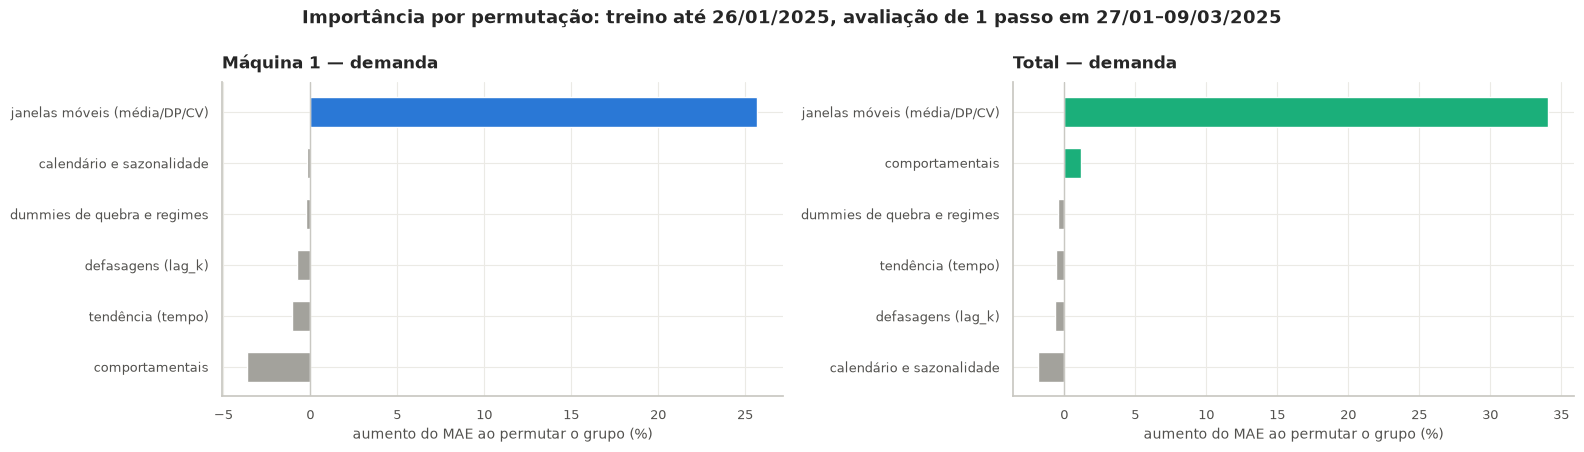

In [7]:
imps = pd.concat([fp.importancia_permutacao(base, det, s, a, ORIGEM - pd.Timedelta(days=42), ORIGEM).assign(série=s, alvo=a)
                  for s in ["Máquina 1", "Total"] for a in ["demanda", "receita"]])
display(imps.round(3))
fig, eixos = plt.subplots(1, 2, figsize=(16, 4.6))
for ax, s in zip(eixos, ["Máquina 1", "Total"]):
    t = imps[(imps["série"] == s) & (imps["alvo"] == "demanda")].set_index("grupo").sort_values("aumento relativo %")
    ax.barh(t.index, t["aumento relativo %"], color=[cor_serie(s) if v > 0 else CORES["contexto"] for v in t["aumento relativo %"]], height=0.6)
    ax.axvline(0, color=CORES["eixo"], lw=1)
    ax.set_xlabel("aumento do MAE ao permutar o grupo (%)")
    ax.set_title(f"{s} — demanda")
fig.suptitle("Importância por permutação: treino até 26/01/2025, avaliação de 1 passo em 27/01–09/03/2025")
fig.tight_layout()
mostrar(fig)

**Leitura:**
- **As janelas móveis (média, desvio e CV recentes) carregam praticamente toda a informação** para a floresta. Permutá-las aumenta o MAE em 24% a 42%.
- Os demais grupos têm importância **≈ 0 ou negativa**: permutá-los não piora, e às vezes melhora levemente. Isso não quer dizer que sejam inúteis para *outros* modelos. As **dummies de quebra são redundantes** para a floresta porque a média móvel de 7–30 dias já "vê" o novo patamar. Para os modelos estatísticos (SARIMAX, contagem), elas são a forma de representar o patamar.
- **Os atributos comportamentais não ajudam a M1** (−2% a −4%) e ajudam pouco o Total (+1% a +2%). Por isso a inclusão deles é **escolhida pela validação interna** da Random Forest (notebook 06), e não imposta.

In [8]:
c = fp.ConstrutorAtributos(base, det, "Máquina 1", ORIGEM)
X = c(base.series[("Máquina 1", "demanda")].loc[:ORIGEM])
cor = fp.correlacao_com_alvo(X, base.series[("Máquina 1", "demanda")].loc[:ORIGEM])
display(cor.head(15).round(2).to_frame("ρ de Spearman com a demanda"))

,ρ de Spearman com a demanda
comp_cartoes_unicos,0.470
media_7,0.470
dp_30,0.470
dp_14,0.440
media_14,0.430
media_30,0.330
regime_240724,0.330
lag_1,0.320
lag_2,0.320
dp_7,0.300


## Síntese

| Decisão | Justificativa |
|---|---|
| Atributos só com o passado; dummies redetectadas em cada origem | testes automáticos de vazamento e de recursão |
| Dummies obrigatórias como **variáveis candidatas** dos modelos estatísticos e atributos da floresta | ΔAIC de −56 (M1) e −113 (Total); saltos de nível, não de tendência (notebook 03) |
| Comportamentais congelados no horizonte e escolhidos pela validação | não são conhecidos para d > T + 1; valor preditivo pequeno ou nulo |
| Sem defasagens cruzadas demanda ↔ receita | exigiriam previsão multivariada recursiva |
| Granularidade diária | < 1 venda por hora |